# Exercise 2 — Classifying transients

*Covers notebooks 01, 03, 04. Difficulty: ★★☆☆☆*

What is the faint limit to classify a transient, how long does a kilonova stay classifiable, and what does a bigger array buy?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 10, "legend.fontsize": 8})

Time-domain and multi-messenger follow-up with a spectrograph is first about **classification**: a
low-SNR spectrum, rebinned to R ~ 100 to 300, that tells a SN Ia from a SN II or a TDE from an AGN
flare. The question for LFAST is *what is the faint limit to classify a transient in a given
exposure?* All times are on-target integration.

Assumptions:
* Classification needs SNR ~ 5 per **rebinned** element at R_bin = 300 across 450 to 650 nm
  (SEDM: Blagorodnova et al. 2018; 4MOST/TiDES: Swann et al. 2019). Co-adding $k = R/R_{bin}$
  adjacent resels of equal SNR raises the SNR by $\sqrt{k}$.
* 60 minutes is the practical upper limit for one classification spectrum.
* Transient SEDs as blackbodies: a hot 25,000 K source (young SN II / TDE), 10,000 K (SN Ia near
  peak) and 3500 K (kilonova at ~3 d, luminous red nova), with magnitudes in Cousins R (Vega); a
  GRB afterglow as a power law $F_\nu \propto \nu^{-0.7}$ in AB.
* Kilonova: AT2017gfo-like, r = 17.3 at 0.5 d at 40 Mpc, fading 0.95 mag per day, cooling from
  10,000 K at 0.5 d to 5000 K at 1.5 d and 2500 K at 5.5 d (Drout et al. 2017; Shappee et al. 2017).
* Grey-time sky, a fair average for target-of-opportunity work where the moon phase is not chosen.

**One cell in this exercise is broken on purpose.** The numbers it produces are wrong by a
constant factor; find out which one and why before you go on.

In [2]:
N_TEL = 20
WINDOW = (450, 650)          # nm, classification window
R_BIN = 300                  # rebinned resolution for classification
SNR_CLASS = 5                # SNR per R_BIN element needed to classify
EXP_MAX = 3600               # s, practical upper limit for one classification spectrum
BAND = "R"                   # magnitudes in Cousins R (~ SDSS r)

bench = LFASTETC("bench_r1800", n_telescopes=N_TEL, wavelength_min_nm=WINDOW[0], wavelength_max_nm=WINDOW[1])
k = bench.instrument.resolving_power / R_BIN   # resels per rebinned element (6)
snr_resel_needed = SNR_CLASS / np.sqrt(k)      # SNR per native resel that gives SNR_CLASS at R_BIN
print(f"{k:.1f} resels per R={R_BIN} bin -> need SNR {snr_resel_needed:.2f} per resel")
# The broken cell asked for SNR 5 per native resel, six times more signal than the R=300 bin needs:
# every exposure time was ~6x too long and every depth ~1 mag too shallow.

seds = {"hot 25,000 K": Source.blackbody(25000, 0, BAND),
        "SN Ia 10,000 K": Source.blackbody(10000, 0, BAND),
        "red 3500 K": Source.blackbody(3500, 0, BAND),
        "afterglow (AB)": Source.powerlaw(-0.7, 0, BAND, system="AB")}

6.0 resels per R=300 bin -> need SNR 2.04 per resel


### 2.1 — Exposure time to classify versus magnitude

Plot the integration time to reach the classification SNR against R magnitude for the four SEDs,
with the 5, 30 and 60 minute lines. Mark the Argus Array detection depths, the discovery engine
LFAST would follow up: **g = 20.0** single-epoch (1 minute) and **g = 21.5** 15-minute co-add
(5 sigma, dark time; Law et al. 2022). How long does a SN Ia at each Argus depth take?

> ✏️ **Before you run the next cell:** a SN Ia-like transient at the Argus single-epoch depth (R ~ 20): classified in 1 minute, 7 minutes or 40 minutes? Write your guess down (or put it in the room poll), then run.

SN Ia: at Argus 1 min depth (20.0): 6.7 min;  at Argus 15 min depth (21.5): 59.7 min


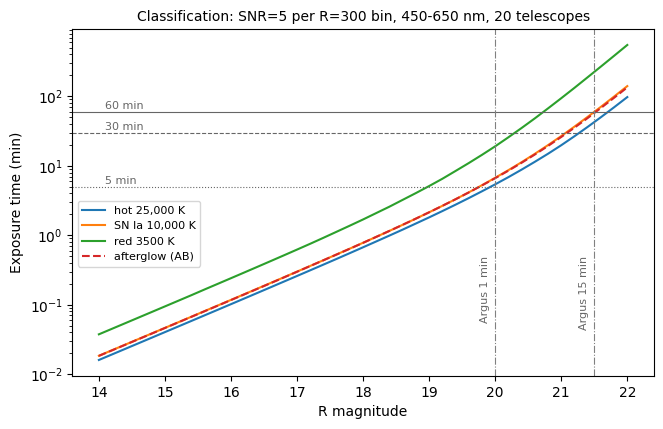

In [3]:
mags = np.linspace(14, 22, 41)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for label, src in seds.items():
    t = bench.exptime_vs_mag(src, mags, snr=snr_resel_needed, wavelength=WINDOW)
    ax.plot(mags, t / 60, label=label, ls="--" if "afterglow" in label else "-")
ax.set_yscale("log"); ax.set_xlabel(f"{BAND} magnitude"); ax.set_ylabel("Exposure time (min)")
for tmin, ls in ((60, "-"), (30, "--"), (5, ":")):
    ax.axhline(tmin, color="0.4", ls=ls, lw=0.8); ax.text(14.1, tmin * 1.1, f"{tmin} min", fontsize=8, color="0.4")
ARGUS = {"Argus 1 min": 20.0, "Argus 15 min": 21.5}
for txt, mag in ARGUS.items():
    ax.axvline(mag, color="0.5", ls="-.", lw=0.8); ax.text(mag - 0.08, 0.5, txt, fontsize=8, color="0.4", rotation=90, ha="right", va="top")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.52))
ax.set_title(f"Classification: SNR={SNR_CLASS} per R={R_BIN} bin, {WINDOW[0]}-{WINDOW[1]} nm, {N_TEL} telescopes")

t_ref = bench.exptime_vs_mag(seds["SN Ia 10,000 K"], list(ARGUS.values()), snr=snr_resel_needed, wavelength=WINDOW)
print("SN Ia: " + ";  ".join(f"at {txt} depth ({mag}): {t / 60:.1f} min" for (txt, mag), t in zip(ARGUS.items(), t_ref)))
# ~7 min at the single-epoch depth, ~1 h at the co-add depth: right at the classification budget.

### 2.2 — Classification depth versus exposure time

Table of the faintest R magnitude that can be classified in 5, 15, 30 and 60 minutes, per SED.
Why does doubling from 30 to 60 minutes gain only ~0.4 mag?

In [4]:
exps = (300, 900, 1800, 3600)
depth = pd.DataFrame({label: [bench.limiting_magnitude(src, t, snr_resel_needed, wavelength=WINDOW) for t in exps]
                      for label, src in seds.items()},
                     index=pd.Index([t // 60 for t in exps], name="exposure (min)"))
depth.round(1)
# Background-limited scaling: 1.25 log10(2) = 0.38 mag. Sky and detector noise dominate at these
# magnitudes, so SNR grows as sqrt(t). The next half magnitude would cost another ~1.5 h.

,"hot 25,000 K","SN Ia 10,000 K",red 3500 K,afterglow (AB)
exposure (min),,,,
5,19.9,19.8,19.0,19.8
15,20.8,20.6,19.8,20.6
30,21.3,21.1,20.3,21.1
60,21.7,21.5,20.7,21.5


### 2.3 — How many days after merger can a kilonova still be classified?

For an AT2017gfo-like kilonova at 40, 100 and 200 Mpc, plot the exposure needed for a
classification spectrum against days after merger (0.5 to 5 d), and print the last day on which
it fits in 30 and 60 minutes. 40 Mpc is GW170817; the LIGO binary-neutron-star range is 150 to
170 Mpc in O4 and 225 to 295 Mpc planned for O5.

 40 Mpc: classifiable until 3.7 d (30 min) / 4.1 d (60 min)
100 Mpc: classifiable until 1.9 d (30 min) / 2.3 d (60 min)
200 Mpc: classifiable until 0.7 d (30 min) / 1.1 d (60 min)


Text(0.5, 1.0, 'AT2017gfo-like kilonova, Bench, 20 telescopes')

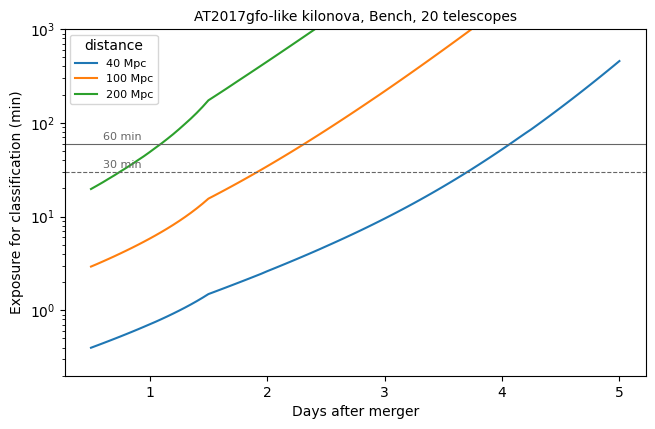

In [5]:
days = np.linspace(0.5, 5, 91)
def kn_mag(d, D_Mpc):
    return 17.3 + 0.95 * (d - 0.5) + 5 * np.log10(D_Mpc / 40)
def kn_teff(d):
    return np.interp(d, [0.5, 1.5, 5.5], [10000, 5000, 2500])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for D in (40, 100, 200):
    t_needed = np.array([bench.exptime_vs_mag(Source.blackbody(kn_teff(d), 0, BAND), [kn_mag(d, D)],
                                              snr=snr_resel_needed, wavelength=WINDOW)[0] for d in days]) / 60
    ax.plot(days, t_needed, label=f"{D} Mpc")
    last = {tmin: days[t_needed <= tmin].max() if (t_needed <= tmin).any() else np.nan for tmin in (30, 60)}
    print(f"{D:3d} Mpc: classifiable until {last[30]:.1f} d (30 min) / {last[60]:.1f} d (60 min)")
ax.axhline(60, color="0.4", lw=0.8); ax.text(0.6, 66, "60 min", fontsize=8, color="0.4")
ax.axhline(30, color="0.4", ls="--", lw=0.8); ax.text(0.6, 33, "30 min", fontsize=8, color="0.4")
ax.set_yscale("log"); ax.set_ylim(0.2, 1e3); ax.set_xlabel("Days after merger"); ax.set_ylabel("Exposure for classification (min)")
ax.legend(title="distance"); ax.set_title(f"AT2017gfo-like kilonova, Bench, {N_TEL} telescopes")
# The kilonova fades ~1 mag/day and cools, moving its flux redward of the 450-650 nm window.

### 2.4 — The array-size trade

With 20, 100 and 200 telescopes (one combiner input per 20, the default), tabulate the 60 minute
classification depth for each SED and the gain over 20. At the faint end every noise term grows
with the number of inputs, so the expected gain is $1.25\log_{10}(N/20)$: 0.9 mag for 100 and
1.25 mag for 200. For the kilonova, what does 1.25 mag mean in distance?

In [6]:
rows = {}
for n in (20, 100, 200):
    e = LFASTETC("bench_r1800", n_telescopes=n, wavelength_min_nm=WINDOW[0], wavelength_max_nm=WINDOW[1])
    rows[n] = {"D_eq (m)": e.telescope.equivalent_diameter_m, "inputs": e.telescope.n_inputs,
               **{label: e.limiting_magnitude(src, EXP_MAX, snr_resel_needed, wavelength=WINDOW) for label, src in seds.items()}}
trade = pd.DataFrame(rows).T.rename_axis("N telescopes")
trade["inputs"] = trade["inputs"].astype(int)
trade["gain vs N=20 (mag)"] = trade["SN Ia 10,000 K"] - trade.loc[20, "SN Ia 10,000 K"]
trade.round(2)
# 1.25 mag is a factor 10**(1.25/5) = 1.8 in distance: 200 telescopes reach at 200 Mpc what 20 reach at ~110 Mpc.

,D_eq (m),inputs,"hot 25,000 K","SN Ia 10,000 K",red 3500 K,afterglow (AB),gain vs N=20 (mag)
N telescopes,,,,,,,
20,3.25,1,21.71,21.50,20.73,21.53,0.00
100,7.26,5,22.61,22.40,21.63,22.42,0.89
200,10.27,10,22.99,22.78,22.01,22.80,1.28


> 🤖 **Ask Jupyter AI:** *Add a GRB afterglow section: for afterglows at R = 17, 19 and 21 (AB) one hour after the burst, fading as t^-1, plot the exposure needed for SNR 10 per native resel (an absorption-line redshift) against the delay from 15 minutes to 48 hours. Which one is still reachable within an hour's integration after 10 hours?*
>
> Then: use Sky(scale=0.4) for dark time and redo the kilonova plot. Does the 200 Mpc curve cross the 30 minute line?

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/lfast-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*